# 02 · Cohort characterisation

What is in the cohort, what is actually measured, and where the outcome signal
lives. Everything here reads the cached cohort — no event tables are touched,
so this notebook is cheap to re-run.

The question behind it: **is there enough structure for a graph to help?** A
patient-similarity GNN only earns its complexity if patients cluster in a way
that carries outcome information beyond each patient's own feature row. That
question is settled in notebook 03; this one assembles the evidence.

In [1]:
exec(open("/kaggle/working/clinical-eegnn/notebooks/src/_bootstrap.py").read())
from src import mimic_iv
from src.data_prep import make_splits, impute_and_scale
import matplotlib.pyplot as plt

cfg = mimic_cfg()
X_raw, y, names, meta = mimic_iv.build_cohort(cfg, verbose=False)
views = meta["views"]
print(f"{len(y):,} patients x {X_raw.shape[1]} features   prevalence {y.mean():.4f}")
print("blocks:", {k: len(v) for k, v in views.items()})

17,663 patients x 331 features   prevalence 0.1078
blocks: {'demographics': 33, 'comorbidity': 19, 'labs': 168, 'vitals': 84, 'treatment': 27}


## Class balance

11% positives is imbalanced but not pathologically so. It is enough that
accuracy is meaningless and AUPRC matters alongside AUROC — a classifier
predicting "survives" for everyone scores 0.89 accuracy and is worthless.

In [2]:
n_pos = int(y.sum())
print(f"died      {n_pos:6,}  ({y.mean():.2%})")
print(f"survived  {len(y)-n_pos:6,}  ({1-y.mean():.2%})")
print(f"\nbaseline AUPRC for a random classifier = prevalence = {y.mean():.4f}")

died       1,904  (10.78%)
survived  15,759  (89.22%)

baseline AUPRC for a random classifier = prevalence = 0.1078


## Missingness

Missingness in the ICU is informative: a lab that was not drawn reflects a
clinical decision that the patient did not look sick enough to warrant it. So
the pipeline keeps missingness indicators rather than discarding the pattern.

If that story is right, missingness should itself correlate with the outcome.

In [3]:
miss = np.isnan(X_raw)
per_block = pd.DataFrame([
    {"block": k, "cols": len(v), "missing_%": 100 * miss[:, v].mean()}
    for k, v in views.items()]).sort_values("missing_%", ascending=False)
print(per_block.to_string(index=False))

# does *being measured at all* predict the outcome?
from sklearn.metrics import roc_auc_score
n_measured = (~miss).sum(axis=1)
print(f"\nAUROC of 'number of features measured' alone: "
      f"{roc_auc_score(y, n_measured):.4f}   (>0.5 means more measurement "
      f"predicts death)")
print(f"  median measured, survived: {np.median(n_measured[y==0]):.0f}")
print(f"  median measured, died    : {np.median(n_measured[y==1]):.0f}")

       block  cols  missing_%
        labs   168  21.693316
      vitals    84  14.621970
   treatment    27   0.000839
demographics    33   0.000000
 comorbidity    19   0.000000



AUROC of 'number of features measured' alone: 0.7026   (>0.5 means more measurement predicts death)
  median measured, survived: 281
  median measured, died    : 306


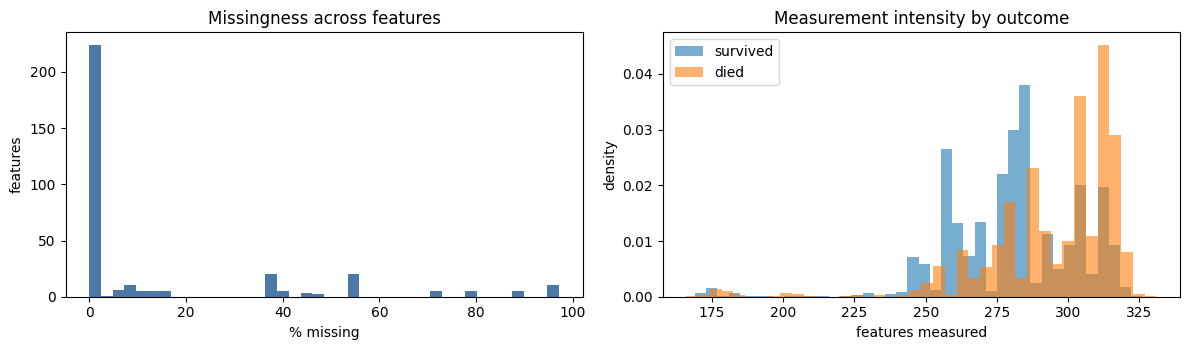

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
per_feature = 100 * miss.mean(axis=0)
ax[0].hist(per_feature, bins=40, color="#4C78A8")
ax[0].set_xlabel("% missing"); ax[0].set_ylabel("features")
ax[0].set_title("Missingness across features")
for s, lab in [(0, "survived"), (1, "died")]:
    ax[1].hist(n_measured[y == s], bins=40, alpha=.6, density=True, label=lab)
ax[1].set_xlabel("features measured"); ax[1].set_ylabel("density")
ax[1].set_title("Measurement intensity by outcome"); ax[1].legend()
plt.tight_layout(); plt.show()

Measurement intensity being predictive is expected and is *not* leakage: it is
recorded within the observation window and reflects care intensity at the time,
which is genuinely prognostic. It does mean the model can lean on process-of-
care signal rather than physiology — worth remembering when the interpretability
notebook attributes importance.

## Where the signal is, by block

Fit a cheap model per block to see what each contributes on its own. This uses
the training split only, so it does not spend test information.

In [5]:
from sklearn.linear_model import LogisticRegression

masks = make_splits(y, cfg["seed"])
train, val, test = masks
print(f"split: train {train.sum():,}  val {val.sum():,}  test {test.sum():,}")
print(f"prevalence  train {y[train].mean():.4f}  val {y[val].mean():.4f}  test {y[test].mean():.4f}")

rows = []
for name, cols in views.items():
    Xb = impute_and_scale(X_raw[:, cols], train)
    lr = LogisticRegression(max_iter=2000, class_weight="balanced")
    lr.fit(Xb[train], y[train])
    rows.append({"block": name, "cols": len(cols),
                 "val_auroc": roc_auc_score(y[val], lr.predict_proba(Xb[val])[:, 1])})

Xall = impute_and_scale(X_raw, train)
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xall[train], y[train])
rows.append({"block": "ALL", "cols": Xall.shape[1],
             "val_auroc": roc_auc_score(y[val], lr.predict_proba(Xall[val])[:, 1])})
print()
print(pd.DataFrame(rows).sort_values("val_auroc", ascending=False).to_string(index=False))

split: train 10,597  val 3,533  test 3,533
prevalence  train 0.1078  val 0.1078  test 0.1078



       block  cols  val_auroc
         ALL   542   0.870108
      vitals    84   0.818018
        labs   168   0.798984
   treatment    27   0.756866
demographics    33   0.734550
 comorbidity    19   0.555938


This table sets the bar the GNN has to clear. A linear model on all blocks is
the honest floor: if the multi-exit graph model cannot beat it, the added
machinery is not paying for itself.

It also shows how much of the signal is redundant across blocks — the "ALL" row
is usually well below the sum of its parts, because vitals, labs and treatment
all measure the same underlying severity.

## Physiology by outcome

Spot-check that the extracted values are clinically sensible. Wrong units or a
mis-mapped `itemid` shows up immediately here.

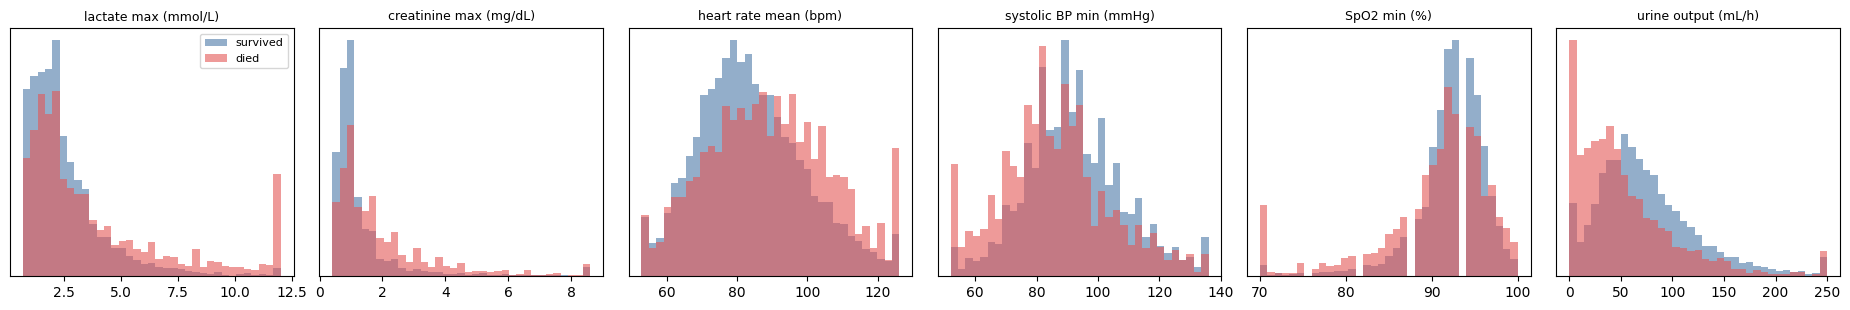

            feature  median_survived  median_died  coverage_%
    lab_lactate_max         2.100000     2.700000   60.550303
 lab_creatinine_max         1.000000     1.400000   98.494027
vit_heart_rate_mean        82.512505    88.349998   99.841477
        vit_sbp_min        91.000000    85.000000   99.671630
       vit_spo2_min        93.000000    92.000000   99.688615
 tx_urine_ml_per_hr        66.250000    41.645836   99.977354


In [6]:
CHECKS = [("lab_lactate_max", "lactate max (mmol/L)"),
          ("lab_creatinine_max", "creatinine max (mg/dL)"),
          ("vit_heart_rate_mean", "heart rate mean (bpm)"),
          ("vit_sbp_min", "systolic BP min (mmHg)"),
          ("vit_spo2_min", "SpO2 min (%)"),
          ("tx_urine_ml_per_hr", "urine output (mL/h)")]
avail = [(c, t) for c, t in CHECKS if c in names]

fig, axes = plt.subplots(1, len(avail), figsize=(3.1 * len(avail), 3.2))
for ax, (col, title) in zip(np.atleast_1d(axes), avail):
    v = X_raw[:, names.index(col)]
    ok = np.isfinite(v)
    lo, hi = np.nanpercentile(v[ok], [1, 99])
    for s, lab, c in [(0, "survived", "#4C78A8"), (1, "died", "#E45756")]:
        sel = ok & (y == s)
        ax.hist(np.clip(v[sel], lo, hi), bins=35, alpha=.6, density=True, label=lab, color=c)
    ax.set_title(title, fontsize=9); ax.set_yticks([])
np.atleast_1d(axes)[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

summary = pd.DataFrame([
    {"feature": c,
     "median_survived": np.nanmedian(X_raw[y == 0, names.index(c)]),
     "median_died": np.nanmedian(X_raw[y == 1, names.index(c)]),
     "coverage_%": 100 * np.isfinite(X_raw[:, names.index(c)]).mean()}
    for c, _ in avail])
print(summary.to_string(index=False))

Expected directions: lactate and creatinine higher in those who died, SpO2 and
systolic BP lower, urine output lower. Any reversal is a mapping bug, not a
finding.

## Criticalness — the auxiliary target

`criticalness` is a continuous severity proxy blended from intervention burden,
length of stay and disposition. It is a **label**, derived from the full stay,
and is only ever read on training nodes inside the loss — never a model input.

Later notebooks use it to define the high-risk stratum for the safety analysis,
which is what fixes the degenerate `high_risk_miss_rate` metric recorded in
HANDOVER §6.1.

count    17663.000000
mean         0.310786
std          0.224798
min          0.000000
25%          0.135971
50%          0.264244
75%          0.428198
max          1.000000

AUROC of criticalness vs mortality: 0.9686
AUROC of severity     vs mortality: 0.7851
correlation(criticalness, severity): 0.6275


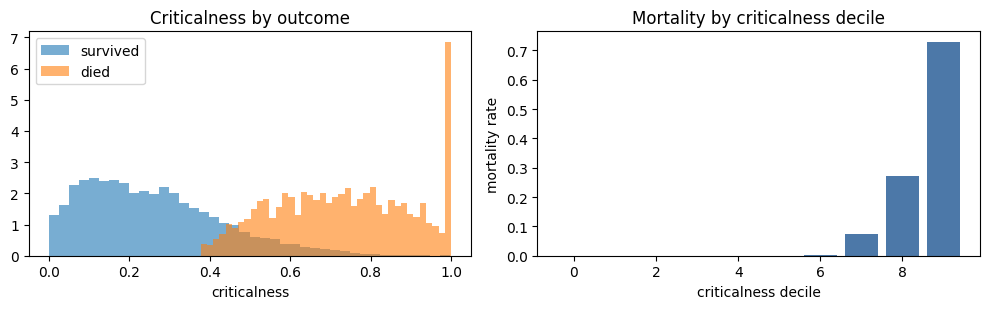

In [7]:
crit = meta["criticalness"]
sev = meta.get("severity")
print(pd.Series(crit).describe().to_string())
print(f"\nAUROC of criticalness vs mortality: {roc_auc_score(y, crit):.4f}")
if sev is not None:
    print(f"AUROC of severity     vs mortality: {roc_auc_score(y, sev):.4f}")
    print(f"correlation(criticalness, severity): {np.corrcoef(crit, sev)[0,1]:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for s, lab in [(0, "survived"), (1, "died")]:
    ax[0].hist(crit[y == s], bins=40, alpha=.6, density=True, label=lab)
ax[0].set_xlabel("criticalness"); ax[0].legend(); ax[0].set_title("Criticalness by outcome")

dec = pd.qcut(crit, 10, labels=False, duplicates="drop")
rate = pd.DataFrame({"dec": dec, "y": y}).groupby("dec")["y"].mean()
ax[1].bar(rate.index, rate.values, color="#4C78A8")
ax[1].set_xlabel("criticalness decile"); ax[1].set_ylabel("mortality rate")
ax[1].set_title("Mortality by criticalness decile")
plt.tight_layout(); plt.show()

### Why `criticalness` cannot be the safety stratum

`_criticalness` blends length of stay, intervention burden and **discharge
disposition**, with the death flag weighted 1.2 against two standardised terms.
The AUROC above shows the consequence: it tracks mortality at ~0.97, so it is
very nearly a copy of the label.

That is acceptable for an auxiliary *training* target — it is a label, used like
any other. It is **not** acceptable as an evaluation stratum. "Top decile of
criticalness" would mean "the patients who died", and the high-risk miss rate
would once again be measuring the threshold rule rather than the model — the
exact degeneracy of HANDOVER §6.1.

So `_severity` is computed separately: organ-support exposure plus physiologic
derangement (vasopressors, ventilation, CRRT, lactate, creatinine, BUN, GCS,
systolic BP, SpO2, respiratory rate), all from inside the observation window,
robust-z-scored and averaged. No outcome, no full-stay information. Its
correlation with criticalness above says how much of "sick" is recoverable from
presenting physiology alone — and the gap between the two AUROCs is a rough
measure of how much of `criticalness` was simply the answer.

The safety stratum in notebooks 05–06 is the top decile of **severity**.

In [8]:
if sev is not None:
    dec_s = pd.qcut(sev, 10, labels=False, duplicates="drop")
    rate_s = pd.DataFrame({"dec": dec_s, "y": y}).groupby("dec")["y"].mean()
    print("mortality by severity decile:")
    print(rate_s.round(4).to_string())
    top = sev >= np.quantile(sev, 0.9)
    print(f"\ntop-decile severity: n={top.sum()}, mortality {y[top].mean():.4f} "
          f"(vs {y.mean():.4f} overall) -- {y[top].mean()/y.mean():.1f}x enriched")
    print("a stratum that is enriched for death but not identical to it is what "
          "makes the safety metric informative")

mortality by severity decile:
dec
0    0.0136
1    0.0232
2    0.0283
3    0.0464
4    0.0617
5    0.0612
6    0.1099
7    0.1444
8    0.2016
9    0.3877

top-decile severity: n=1767, mortality 0.3877 (vs 0.1078 overall) -- 3.6x enriched
a stratum that is enriched for death but not identical to it is what makes the safety metric informative


A monotone rise across deciles is what makes a score usable as a risk stratum.
The top decile of `severity` is the group the safety metric is defined against —
patients where an early, shallow exit is most dangerous.

In [9]:
json.dump({
    "prevalence": float(y.mean()),
    "block_val_auroc": {r["block"]: float(r["val_auroc"]) for r in rows},
    "missing_by_block": per_block.set_index("block")["missing_%"].to_dict(),
    "auroc_measurement_intensity": float(roc_auc_score(y, n_measured)),
    "auroc_criticalness": float(roc_auc_score(y, crit)),
}, open(f"{CACHE}/eda_summary.json", "w"), indent=2)
print("wrote eda_summary.json")

wrote eda_summary.json


**Next:** `03_graph_construction` builds the patient-similarity graph and tests
whether it carries outcome structure — the precondition for the whole approach.